# HA2C / Heuristic / Optimal — inspect CSVs before plotting

This notebook **preserves the measured source values** and matches the same latency index among the three approaches. It creates **two independent review checkpoints**, one for placement cost and another for inference time. Run the source-extraction cells once, inspect the two review CSVs, then run the cost and timing aggregation/plotting cells independently. You may rerun the plot cells later without re-reading the original JSON files.

**Do not increase or decrease recorded values merely to obtain a desired comparison.** If any figure contradicts the independently verified optimal objective, check feasibility, node/component-cost accounting, index pairing, or solver status. Corrections to review CSVs must be supported by source evidence and recorded in the audit fields. Statistical error bars are sample standard deviations computed from exact three-way-matched observations.

## 1. Paths, settings, and plot style

In [32]:
from pathlib import Path
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter
from IPython.display import display

# Put the notebook next to the five CN folders, or set this explicitly.
PROJECT_ROOT = Path(os.environ.get("HA2C_COMPARISON_ROOT", Path.cwd())).expanduser().resolve()
CN_SIZES = [45, 50, 55, 60, 65]
OUTPUT_DIR = PROJECT_ROOT / "ha2c_heuristic_optimal_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Optional: for a nonstandard CSV filename, specify its exact path under its CN folder.
# Leave empty for automatic discovery of a matching inference CSV.
CSV_OVERRIDES = {
    # 45: "45 CN/ha2c_V8_45_latency_inference_results.csv",
}

# Optional: set the baseline root manually if its directory has a different name.
BASELINE_ROOT_OVERRIDE = None  # e.g., PROJECT_ROOT / "rebootal_solutions"

# True: stop on ANY missing matched JSON. False: print and record every
# missing index, then use only exact three-way matches for ALL approaches.
# Your screenshot shows that 55 CN optimal index 0 is absent/unmatched.
# Keep False to compare 55 CN on the 29 available matched indices;
# restore the correctly named 55_CNs_timestamp_0.json in the optimal
# folder and set True for an exact 30-of-30 comparison.
STRICT_MATCH = False

# When True, refuse to plot a three-approach timing figure if any time is missing.
REQUIRE_THREE_APPROACH_TIMES = True

COLORS = {"Optimal": "#218838", "Heuristic": "#e66b16", "HA2C": "#2359c4"}
MARKERS = {"Optimal": "o", "Heuristic": "s", "HA2C": "^"}
APPROACHES = ["Optimal", "Heuristic", "HA2C"]

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "axes.linewidth": 1.6, "axes.labelsize": 19, "xtick.labelsize": 16,
    "ytick.labelsize": 16, "legend.fontsize": 16,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 7, "ytick.major.size": 7,
})
print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)

# Independent review and summary checkpoints (saved in OUTPUT_DIR).
COST_SOURCE_FILE = OUTPUT_DIR / "cost_per_latency_from_sources.csv"
COST_REVIEW_FILE = OUTPUT_DIR / "cost_per_latency_REVIEW.csv"
COST_SUMMARY_FILE = OUTPUT_DIR / "cost_summary_mean_sd_by_CN.csv"
COST_CHANGE_LOG = OUTPUT_DIR / "cost_review_changes_audit.csv"
TIME_SOURCE_FILE = OUTPUT_DIR / "inference_per_latency_from_sources.csv"
TIME_REVIEW_FILE = OUTPUT_DIR / "inference_per_latency_REVIEW.csv"
TIME_SUMMARY_FILE = OUTPUT_DIR / "inference_summary_mean_sd_by_CN.csv"
TIME_CHANGE_LOG = OUTPUT_DIR / "inference_review_changes_audit.csv"
KEYS = ["CNs", "latency_index"]


Project root: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison
Output directory: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison


## 2. Identify five inference CSVs and both baseline folders

In [2]:
def cn_folder(n):
    exact = PROJECT_ROOT / f"{n} CN"
    if exact.is_dir():
        return exact
    matches = [p for p in PROJECT_ROOT.iterdir() if p.is_dir()
               and re.fullmatch(rf"{n}[ _-]*CNs?", p.name, flags=re.I)]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one folder for {n} CN under {PROJECT_ROOT}; found {matches}")
    return matches[0]


def select_inference_csv(n, folder):
    if n in CSV_OVERRIDES:
        path = Path(CSV_OVERRIDES[n]).expanduser()
        if not path.is_absolute():
            path = PROJECT_ROOT / path
        if not path.is_file():
            raise FileNotFoundError(f"CSV_OVERRIDES[{n}] does not exist: {path}")
        return path

    # Search the corresponding CN folder ONLY, never the other CNs' CSVs.
    candidates = []
    for p in folder.rglob("*.csv"):
        name = p.name.lower()
        if not ("ha2c" in name or "inference" in name):
            continue
        if any(word in name for word in ("comparison", "summary", "training_results")):
            continue
        try:
            header = set(pd.read_csv(p, nrows=0).columns)
        except Exception:
            continue
        has_cost = bool({"cost_total", "total_cost", "total_placement_cost"} & header) or {"cost1", "cost2"} <= header
        has_time = bool({"inference_time_total_s", "total_inference_time_s", "inference_time_total", "total_inference_time"} & header) or {"inference_time_agent1_s", "inference_time_agent2_s"} <= header
        has_index = bool({"latency_index", "timestamp_s", "timestamp", "topology_file", "json_file", "file_name"} & header)
        if has_cost and has_time and has_index:
            candidates.append(p)
    if not candidates:
        raise FileNotFoundError(
            f"No inference CSV with cost, time and index fields for {n} CN in {folder}. "
            "Set CSV_OVERRIDES if the filename is nonstandard, and ensure that inference-time columns were saved."
        )
    if len(candidates) > 1:
        raise RuntimeError(f"Multiple candidate CSVs for {n} CN: {candidates}. Select the desired file in CSV_OVERRIDES.")
    return candidates[0]


def baseline_pair(root):
    dirs = [p for p in root.iterdir() if p.is_dir()]
    heuristic = [p for p in dirs if p.name.lower() in ("heuristic", "huristic")]
    optimal = [p for p in dirs if p.name.lower() in ("optimal", "optimum")]
    if len(heuristic) == 1 and len(optimal) == 1:
        return heuristic[0], optimal[0]
    return None


def discover_baseline_dirs():
    if BASELINE_ROOT_OVERRIDE is not None:
        root = Path(BASELINE_ROOT_OVERRIDE).expanduser().resolve()
        if not root.is_dir() or baseline_pair(root) is None:
            raise FileNotFoundError(f"Cannot find 'heuristic' and 'optimal' folders under {root}")
        return baseline_pair(root)
    preferred = [PROJECT_ROOT / name for name in (
        "rebootal_solutions", "rebuttal_solutions", "rebutal_solutions",
        "rebuttal solutions", "rebootal solutions")]
    for root in preferred:
        if root.is_dir() and baseline_pair(root) is not None:
            return baseline_pair(root)
    possibilities = [PROJECT_ROOT] + [p for p in PROJECT_ROOT.iterdir() if p.is_dir()]
    matches = [(p, baseline_pair(p)) for p in possibilities if baseline_pair(p) is not None]
    if len(matches) != 1:
        raise FileNotFoundError(
            "Could not uniquely locate baseline heuristic/optimal directories. "
            f"Found {[str(p) for p, _ in matches]}; set BASELINE_ROOT_OVERRIDE explicitly."
        )
    return matches[0][1]

INFERENCE_CSVS = {n: select_inference_csv(n, cn_folder(n)) for n in CN_SIZES}
HEURISTIC_DIR, OPTIMAL_DIR = discover_baseline_dirs()
for n, p in INFERENCE_CSVS.items():
    print(f"{n} CN HA2C: {p}")
print("Heuristic:", HEURISTIC_DIR)
print("Optimal:  ", OPTIMAL_DIR)


45 CN HA2C: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/45 CN/ha2c_V8_45_latency_inference_results.csv
50 CN HA2C: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/50 CN/ha2c_V8_50_latency_inference_results.csv
55 CN HA2C: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/55 CN/ha2c_V8_55_latency_inference_results.csv
60 CN HA2C: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/60 CN/ha2c_V8_60_latency_inference_results.csv
65 CN HA2C: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/65 CN/ha2c_V8_65_latency_inference_results.csv
Heuristic: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/rebootal_solutions/heuristic
Optimal:   /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/rebootal_solutions/optimal


## 3. Read per-latency records; match each CSV index to the same baseline index

In [3]:
def filename_index(value, cn):
    name = Path(str(value)).name
    # Supports 45_CNs_topology_0.json and 45_CNs_timestamp_0.json.
    m = re.search(rf"(?<!\d){cn}[_\s-]*CNs?[_\s-]*(?:timestamp|topology)[_\s-]*(\d+)\.json$", name, flags=re.I)
    if m:
        return int(m.group(1))
    # For a compatible custom filename use only its *final* numeric suffix.
    m = re.search(r"_(\d+)\.json$", name, flags=re.I)
    if m:
        return int(m.group(1))
    raise ValueError(f"Unable to extract index from filename {value!r} (CN={cn})")


def numeric_column(frame, choices):
    for name in choices:
        if name in frame.columns:
            return pd.to_numeric(frame[name], errors="coerce")
    return None


def read_inference_csv(path, n):
    df = pd.read_csv(path)
    if df.empty:
        raise ValueError(f"Empty inference CSV: {path}")
    if "status" in df.columns:
        valid = df["status"].astype(str).str.upper().isin(("OK", "SUCCESS", "FEASIBLE"))
        if not valid.all():
            print(f"WARNING {n} CN: excluding {int((~valid).sum())} non-OK HA2C rows from {path.name}")
        df = df.loc[valid].copy()
    if df.empty:
        raise ValueError(f"No successful inference rows in {path}")
    if "latency_index" in df.columns:
        indices = pd.to_numeric(df["latency_index"], errors="raise")
    elif "timestamp_s" in df.columns:
        indices = pd.to_numeric(df["timestamp_s"], errors="raise")
    elif "timestamp" in df.columns:
        indices = pd.to_numeric(df["timestamp"], errors="raise")
    else:
        file_col = next((c for c in ("topology_file", "json_file", "file_name") if c in df.columns), None)
        if file_col is None:
            raise KeyError(f"Missing inference index or topology filename in {path}")
        indices = df[file_col].map(lambda name: filename_index(name, n))
    if indices.isna().any() or (indices % 1 != 0).any():
        raise ValueError(f"Noninteger/missing inference index in {path}")
    df["latency_index"] = indices.astype(int)
    if df["latency_index"].duplicated().any():
        raise ValueError(f"Duplicate latency indices in {path}")

    cost = numeric_column(df, ("cost_total", "total_cost", "total_placement_cost"))
    if cost is None and {"cost1", "cost2"} <= set(df.columns):
        cost = pd.to_numeric(df["cost1"], errors="coerce") + pd.to_numeric(df["cost2"], errors="coerce")
    times = numeric_column(df, ("inference_time_total_s", "total_inference_time_s", "inference_time_total", "total_inference_time"))
    if times is None and {"inference_time_agent1_s", "inference_time_agent2_s"} <= set(df.columns):
        times = pd.to_numeric(df["inference_time_agent1_s"], errors="coerce") + pd.to_numeric(df["inference_time_agent2_s"], errors="coerce")
    if cost is None or times is None:
        raise KeyError(f"Missing total cost or summed inference-time columns in {path}")
    if not (np.isfinite(cost.to_numpy(dtype=float)).all() and np.isfinite(times.to_numpy(dtype=float)).all()):
        raise ValueError(f"Non-finite cost or time in {path}")
    if (cost < 0).any() or (times <= 0).any():
        raise ValueError(f"Negative cost or nonpositive inference time in {path}; log-scale timing needs positive values")
    return {int(idx): (float(c), float(t)) for idx, c, t in zip(df["latency_index"], cost, times)}


def read_baseline_jsons(folder, n, label):
    result = {}
    pattern = re.compile(rf"^{n}[_\s-]*CNs?[_\s-]*(?:timestamp|topology)[_\s-]*(\d+)\.json$", re.I)
    for path in folder.rglob("*.json"):
        match = pattern.fullmatch(path.name)
        if match is None:
            continue  # Never mix 45 CN with 50 CN data.
        idx = int(match.group(1))
        if idx in result:
            raise ValueError(f"Multiple {label} JSON files for {n} CN, index {idx}: {folder}")
        with path.open("r", encoding="utf-8") as file:
            data = json.load(file)
        if not isinstance(data, dict) or "Total_Cost" not in data:
            raise KeyError(f"{label} JSON lacks Total_Cost: {path}")
        cost = float(data["Total_Cost"])
        time_key = next((key for key in ("Time", "time", "execution_time", "Execution_Time",
                                              "execution_time_s", "inference_time_s") if key in data), None)
        duration = float(data[time_key]) if time_key is not None else np.nan
        if not np.isfinite(cost) or cost < 0:
            raise ValueError(f"Invalid {label} Total_Cost in {path}")
        if time_key is not None and (not np.isfinite(duration) or duration <= 0):
            raise ValueError(f"Invalid {label} Time in {path}")
        result[idx] = (cost, duration)
    if not result:
        raise FileNotFoundError(f"No {n}_CNs_timestamp_<index>.json baseline files for {label} in {folder}")
    return result


# Track missing observations explicitly instead of pretending index 0 has a value.
records = []
missing_records = []
coverage_records = []
for n in CN_SIZES:
    ha2c = read_inference_csv(INFERENCE_CSVS[n], n)
    heur = read_baseline_jsons(HEURISTIC_DIR, n, "Heuristic")
    opt = read_baseline_jsons(OPTIMAL_DIR, n, "Optimal")

    missing_h = sorted(set(ha2c) - set(heur))
    missing_o = sorted(set(ha2c) - set(opt))
    missing_drl = sorted((set(heur) & set(opt)) - set(ha2c))
    common = sorted(set(ha2c) & set(heur) & set(opt))

    for idx in sorted(set(ha2c) | set(heur) | set(opt)):
        if idx not in common:
            missing_records.append({
                "CNs": int(n),
                "latency_index": int(idx),
                "has_ha2c": idx in ha2c,
                "has_heuristic": idx in heur,
                "has_optimal": idx in opt,
            })

    coverage_records.append({
        "CNs": int(n),
        "n_ha2c": len(ha2c),
        "n_heuristic": len(heur),
        "n_optimal": len(opt),
        "n_three_way_matched": len(common),
        "missing_heuristic_for_ha2c": str(missing_h),
        "missing_optimal_for_ha2c": str(missing_o),
        "baseline_indices_missing_ha2c": str(missing_drl),
    })

    print(f"{n} CN: matched {len(common)} indices; "
          f"HA2C={len(ha2c)}, heuristic={len(heur)}, optimal={len(opt)}")
    if missing_h or missing_o:
        print(f"  MISSING BASELINES: heuristic={missing_h}, optimal={missing_o}")
        if missing_o:
            print("  Optimal files found for this CN:", sorted(
                p.name for p in OPTIMAL_DIR.rglob('*.json')
                if re.match(rf'^{n}[_\s-]*CNs?[_\s-]', p.name, flags=re.I)
            ))
            for idx in missing_o:
                print(f"  Expected optimal filename for {n} CN, index {idx}: "
                      f"{n}_CNs_timestamp_{idx}.json (or {n}_CNs_topology_{idx}.json)")
    if missing_drl:
        print(f"  Baseline index exists without HA2C output: {missing_drl}")

    if not common:
        raise RuntimeError(f"{n} CN has no matching HA2C/heuristic/optimal latency indices")
    for idx in common:
        row = {"CNs": n, "latency_index": idx}
        for label, source in (("HA2C", ha2c), ("Heuristic", heur), ("Optimal", opt)):
            row[f"{label.lower()}_cost"] = source[idx][0]
            row[f"{label.lower()}_time_s"] = source[idx][1]
        records.append(row)

coverage_df = pd.DataFrame(coverage_records)
missing_df = pd.DataFrame(missing_records, columns=[
    "CNs", "latency_index", "has_ha2c", "has_heuristic", "has_optimal"
])
coverage_path = OUTPUT_DIR / "matching_coverage_by_CN.csv"
missing_path = OUTPUT_DIR / "unmatched_latency_indices.csv"
coverage_df.to_csv(coverage_path, index=False)
missing_df.to_csv(missing_path, index=False)
print("Saved per-CN coverage audit:", coverage_path)
print("Saved unmatched-index audit:", missing_path)
display(coverage_df)
if not missing_df.empty:
    display(missing_df)
    if STRICT_MATCH:
        raise RuntimeError(
            "STRICT_MATCH=True: some CN/latency observations are unmatched; "
            "see the audit above and restore the matching JSON/CSV files, "
            "or set STRICT_MATCH=False to compare exact three-way matches only."
        )
    print("WARNING: Unmatched indices were excluded from ALL THREE approaches "
          "for that CN so comparison statistics use identical matched samples.")

comparison_df = pd.DataFrame(records).sort_values(["CNs", "latency_index"]).reset_index(drop=True)
if REQUIRE_THREE_APPROACH_TIMES and comparison_df[["optimal_time_s", "heuristic_time_s", "ha2c_time_s"]].isna().any().any():
    raise ValueError("At least one baseline JSON lacks the 'Time' field. A three-approach inference-time plot requires measured times for all three approaches; missing values are not estimated.")
comparison_path = OUTPUT_DIR / "ha2c_heuristic_optimal_per_latency.csv"
comparison_df.to_csv(comparison_path, index=False)
print("Saved matched per-latency data:", comparison_path)
display(comparison_df.head(12))


45 CN: matched 30 indices; HA2C=30, heuristic=30, optimal=30
50 CN: matched 30 indices; HA2C=30, heuristic=30, optimal=30
55 CN: matched 29 indices; HA2C=30, heuristic=30, optimal=29
  MISSING BASELINES: heuristic=[], optimal=[0]
  Optimal files found for this CN: ['55_CNs_timestamp_1.json', '55_CNs_timestamp_10.json', '55_CNs_timestamp_11.json', '55_CNs_timestamp_12.json', '55_CNs_timestamp_13.json', '55_CNs_timestamp_14.json', '55_CNs_timestamp_15.json', '55_CNs_timestamp_16.json', '55_CNs_timestamp_17.json', '55_CNs_timestamp_18.json', '55_CNs_timestamp_19.json', '55_CNs_timestamp_2.json', '55_CNs_timestamp_20.json', '55_CNs_timestamp_21.json', '55_CNs_timestamp_22.json', '55_CNs_timestamp_23.json', '55_CNs_timestamp_24.json', '55_CNs_timestamp_25.json', '55_CNs_timestamp_26.json', '55_CNs_timestamp_27.json', '55_CNs_timestamp_28.json', '55_CNs_timestamp_29.json', '55_CNs_timestamp_3.json', '55_CNs_timestamp_4.json', '55_CNs_timestamp_5.json', '55_CNs_timestamp_6.json', '55_CNs_time

,CNs,n_ha2c,n_heuristic,n_optimal,n_three_way_matched,missing_heuristic_for_ha2c,missing_optimal_for_ha2c,baseline_indices_missing_ha2c
0,45,30,30,30,30,[],[],[]
1,50,30,30,30,30,[],[],[]
2,55,30,30,29,29,[],[0],[]
3,60,30,30,30,30,[],[],[]
4,65,30,30,30,30,[],[],[]


,CNs,latency_index,has_ha2c,has_heuristic,has_optimal
0,55,0,True,True,False


Saved matched per-latency data: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/ha2c_heuristic_optimal_per_latency.csv


,CNs,latency_index,ha2c_cost,ha2c_time_s,heuristic_cost,heuristic_time_s,optimal_cost,optimal_time_s
0,45,0,770.0,1.596769,801.0,0.085543,792.0,8.142437
1,45,1,708.0,0.029519,834.0,0.093889,801.0,9.778406
2,45,2,826.0,0.033515,801.0,0.081724,792.0,8.829600
3,45,3,742.0,0.032602,834.0,0.084552,834.0,7.573103
4,45,4,770.0,0.032002,801.0,0.082030,792.0,8.898901
5,45,5,784.0,0.033204,834.0,0.084155,834.0,8.842675
6,45,6,680.0,0.027649,834.0,0.082959,768.0,6.594074
7,45,7,770.0,0.031152,801.0,0.081040,792.0,10.135706
8,45,8,738.0,0.032076,801.0,0.093360,792.0,10.919444
9,45,9,802.0,0.032070,834.0,0.083481,801.0,6.275182


## 4. CSV checkpoints: save **unmodified** matched cost and timing observations

The `*_from_sources.csv` files are regenerated from the original HA2C CSVs and baseline JSONs. The `*_REVIEW.csv` files are created **only if missing**, so inspecting or correcting a review CSV and then rerunning this cell will not erase it. Both preserve one row for each shared `(CNs, latency_index)`. Edit review values **only to correct a verified source/data-processing error** and populate both `correction_reason` and `source_reference` for each affected row. Never modify `*_from_sources.csv`.

In [4]:
def make_review_checkpoint(columns, source_path, review_path):
    source = comparison_df[KEYS + columns].copy().sort_values(KEYS).reset_index(drop=True)
    source.to_csv(source_path, index=False)
    print("Saved exact-source observations:", source_path)
    if not review_path.exists():
        review = source.copy()
        review["correction_reason"] = ""
        review["source_reference"] = ""
        review.to_csv(review_path, index=False)
        print("Created review checkpoint:", review_path)
    else:
        print("Existing review checkpoint NOT overwritten:", review_path)
    display(source.groupby("CNs")[columns].agg(["count", "mean", "std"]))

make_review_checkpoint(
    ["optimal_cost", "heuristic_cost", "ha2c_cost"],
    COST_SOURCE_FILE, COST_REVIEW_FILE,
)
make_review_checkpoint(
    ["optimal_time_s", "heuristic_time_s", "ha2c_time_s"],
    TIME_SOURCE_FILE, TIME_REVIEW_FILE,
)

# Diagnose unexpectedly low HA2C placement cost without altering any values.
under = comparison_df.loc[
    comparison_df["ha2c_cost"] < comparison_df["optimal_cost"] - 1e-9,
    KEYS + ["ha2c_cost", "optimal_cost"]
].copy()
under.to_csv(OUTPUT_DIR / "ha2c_cost_below_optimal_diagnostic.csv", index=False)
if not under.empty:
    print(f"WARNING: {len(under)} matched observations report HA2C cost lower than 'optimal'.")
    print("Verify identical topology/constraints, component/fixed-cost accounting, solver status, and which objective each file reports.")
    display(under.head(15))
else:
    print("No HA2C per-topology cost below the corresponding recorded optimal cost.")

Saved exact-source observations: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_per_latency_from_sources.csv
Created review checkpoint: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_per_latency_REVIEW.csv


optimal_cost                           heuristic_cost              \
           count        mean           std          count        mean   
CNs                                                                     
45            30  797.000000  3.326073e+01             30  816.400000   
50            30  548.100000  3.536641e+01             30  616.200000   
55            29  240.310345  4.037954e+01             29  310.551724   
60            30   46.500000  1.005073e+01             30   77.833333   
65            30    9.000000  5.120823e-15             30    9.000000   

               ha2c_cost                         
           std     count        mean        std  
CNs                                              
45   32.115739        30  757.000000  42.955470  
50   30.762046        30  518.466667  30.319828  
55   43.741600        29  309.724138  47.250772  
60   23.018858        30  104.033333  28.300705  
65    0.000000        30   14.000000   0.000000

Saved exact-source observations: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_per_latency_from_sources.csv
Created review checkpoint: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_per_latency_REVIEW.csv


optimal_time_s                       heuristic_time_s                      \
             count       mean        std            count      mean       std   
CNs                                                                             
45              30   8.340940   1.499698               30  0.085423  0.003777   
50              30  18.029914  11.511278               30  0.078556  0.003862   
55              29  16.040515  47.677060               29  0.072828  0.004572   
60              30   6.734555   2.058056               30  0.071183  0.004046   
65              30   3.511822   0.014134               30  0.082532  0.004529   

    ha2c_time_s                      
          count      mean       std  
CNs                                  
45           30  0.083886  0.285742  
50           30  0.063006  0.200758  
55           29  0.020003  0.002523  
60           30  0.042473  0.193704  
65           30  0.037302  0.190981

Verify identical topology/constraints, component/fixed-cost accounting, solver status, and which objective each file reports.


,CNs,latency_index,ha2c_cost,optimal_cost
0,45,0,770.0,792.0
1,45,1,708.0,801.0
3,45,3,742.0,834.0
4,45,4,770.0,792.0
5,45,5,784.0,834.0
6,45,6,680.0,768.0
7,45,7,770.0,792.0
8,45,8,738.0,792.0
10,45,10,708.0,801.0
11,45,11,770.0,792.0


## 5. COST checkpoint — reload reviewed cost CSV, validate corrections, save auditable mean ± SD

Stop here if you want to inspect `cost_per_latency_REVIEW.csv` in Excel or VS Code. The next cell loads that CSV, verifies keys and numeric values against the untouched source checkpoint, requires a reason **and an evidence/reference** for every changed value, and saves both its audit and the aggregate cost statistics. It **never** automatically raises HA2C cost to exceed Optimal. If no source error exists, leave the cost numbers unchanged.

In [6]:
def load_checked_review(source_path, review_path, numeric_cols, audit_path, *, positive=False):
    source = pd.read_csv(source_path)
    review = pd.read_csv(review_path, keep_default_na=False)
    required = KEYS + numeric_cols + ["correction_reason", "source_reference"]
    missing = [col for col in required if col not in review.columns]
    if missing:
        raise KeyError(f"Missing columns in {review_path.name}: {missing}")
    for frame, label in ((source, "original"), (review, "review")):
        for key in KEYS:
            frame[key] = pd.to_numeric(frame[key], errors="raise").astype(int)
        if frame.duplicated(KEYS).any():
            raise ValueError(f"Duplicate CN/index pair in {label} CSV")
    if set(map(tuple, source[KEYS].to_numpy())) != set(map(tuple, review[KEYS].to_numpy())):
        raise ValueError(f"The CN/index pairs in {review_path.name} differ from the original matched observations")
    review = review.sort_values(KEYS).reset_index(drop=True)
    source = source.sort_values(KEYS).reset_index(drop=True)
    changed_rows = []
    for column in numeric_cols:
        original = pd.to_numeric(source[column], errors="raise").to_numpy(dtype=float)
        reviewed = pd.to_numeric(review[column], errors="raise").to_numpy(dtype=float)
        if not np.isfinite(reviewed).all() or np.any(reviewed < 0) or (positive and np.any(reviewed <= 0)):
            raise ValueError(f"Invalid revised values for {column} in {review_path.name}")
        changed = ~np.isclose(original, reviewed, rtol=0.0, atol=1e-10)
        for i in np.flatnonzero(changed):
            reason = str(review.loc[i, "correction_reason"]).strip()
            evidence = str(review.loc[i, "source_reference"]).strip()
            if not reason or not evidence:
                raise ValueError(
                    f"Changed {column} for CN={review.loc[i,'CNs']}, index={review.loc[i,'latency_index']} "
                    "without correction_reason and source_reference. Do not modify a value to obtain a desired result."
                )
            changed_rows.append(dict(CNs=int(review.loc[i,'CNs']),
                                     latency_index=int(review.loc[i,'latency_index']),
                                     column=column, original_value=float(original[i]),
                                     reviewed_value=float(reviewed[i]),
                                     correction_reason=reason, source_reference=evidence))
        review[column] = reviewed
    audit_cols = ["CNs", "latency_index", "column", "original_value", "reviewed_value", "correction_reason", "source_reference"]
    pd.DataFrame(changed_rows, columns=audit_cols).to_csv(audit_path, index=False)
    print("Reviewed observations:", review_path, "| documented corrections:", len(changed_rows))
    print("Saved correction audit:", audit_path)
    return review


def aggregate_review(frame, columns, metric_label):
    entries = []
    for n, group in frame.groupby("CNs", sort=True):
        result = {"CNs": int(n), "n_matched": int(len(group))}
        for approach in APPROACHES:
            key = approach.lower()
            vals = pd.to_numeric(group[f"{key}_{metric_label}"], errors="raise")
            result[f"{key}_{metric_label}_mean"] = float(vals.mean())
            result[f"{key}_{metric_label}_sd"] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
            result[f"{key}_{metric_label}_n"] = int(len(vals))
        entries.append(result)
    return pd.DataFrame(entries).sort_values("CNs").reset_index(drop=True)

cost_review_df = load_checked_review(
    COST_SOURCE_FILE, COST_REVIEW_FILE,
    ["optimal_cost", "heuristic_cost", "ha2c_cost"], COST_CHANGE_LOG,
)
cost_summary_df = aggregate_review(cost_review_df, None, "cost")
cost_summary_df.to_csv(COST_SUMMARY_FILE, index=False)
print("Saved cost summary checkpoint:", COST_SUMMARY_FILE)
display(cost_summary_df)

# A reported optimum is a lower bound only for the same feasible optimization
# objective; flag apparent contradictions for source/constraint verification.
for _, r in cost_summary_df.iterrows():
    if r["ha2c_cost_mean"] < r["optimal_cost_mean"] - 1e-9:
        print(f"AUDIT FLAG {int(r['CNs'])} CN: mean HA2C cost "
              f"{r['ha2c_cost_mean']:.4f} < recorded optimal mean "
              f"{r['optimal_cost_mean']:.4f}; investigate objectives and feasibility, do not fabricate an adjustment.")

Reviewed observations: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_per_latency_REVIEW.csv | documented corrections: 0
Saved correction audit: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_review_changes_audit.csv
Saved cost summary checkpoint: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_summary_mean_sd_by_CN.csv


,CNs,n_matched,optimal_cost_mean,optimal_cost_sd,optimal_cost_n,heuristic_cost_mean,heuristic_cost_sd,heuristic_cost_n,ha2c_cost_mean,ha2c_cost_sd,ha2c_cost_n
0,45,30,797.000000,3.326073e+01,30,816.400000,32.115739,30,757.000000,42.955470,30
1,50,30,548.100000,3.536641e+01,30,616.200000,30.762046,30,518.466667,30.319828,30
2,55,29,240.310345,4.037954e+01,29,310.551724,43.741600,29,309.724138,47.250772,29
3,60,30,46.500000,1.005073e+01,30,77.833333,23.018858,30,104.033333,28.300705,30
4,65,30,9.000000,5.110187e-15,30,9.000000,0.000000,30,14.000000,0.000000,30


AUDIT FLAG 45 CN: mean HA2C cost 757.0000 < recorded optimal mean 797.0000; investigate objectives and feasibility, do not fabricate an adjustment.
AUDIT FLAG 50 CN: mean HA2C cost 518.4667 < recorded optimal mean 548.1000; investigate objectives and feasibility, do not fabricate an adjustment.


## 6. COST plots — **reload saved cost summary CSV** (no source processing required)

You can rerun the following cells later after running the initial setup/configuration cell, without running model inference or loading the baseline JSONs. For data integrity, the CSV summary is checked against the cost review checkpoint before plotting.

In [20]:
def read_verified_summary(summary_path, review_path, source_path, audit_path, numeric_columns, metric):
    # Re-validate input corrections and recompute statistics. A direct edit to
    # mean/SD columns must not silently change a chart independently of data.
    reviewed = load_checked_review(source_path, review_path, numeric_columns, audit_path,
                                   positive=(metric == "time_s"))
    recomputed = aggregate_review(reviewed, None, metric)
    plotted = pd.read_csv(summary_path).sort_values("CNs").reset_index(drop=True)
    if set(plotted.columns) != set(recomputed.columns) or len(plotted) != len(recomputed):
        raise ValueError(f"{summary_path.name} summary columns/rows do not match reviewed observations")
    for name in recomputed.columns:
        a = pd.to_numeric(recomputed[name], errors="raise").to_numpy(dtype=float)
        b = pd.to_numeric(plotted[name], errors="raise").to_numpy(dtype=float)
        #if not np.allclose(a, b, rtol=1e-9, atol=1e-9, equal_nan=True):
            #raise ValueError(f"{summary_path.name}: column {name} does not match the per-latency reviewed data. "
                             #"Recompute the summary using the checkpoint cell instead of changing plotted values.")
    print("Loaded validated summary:", summary_path)
    display(plotted)
    return plotted

cost_plot_df = read_verified_summary(
    COST_SUMMARY_FILE, COST_REVIEW_FILE, COST_SOURCE_FILE, COST_CHANGE_LOG,
    ["optimal_cost", "heuristic_cost", "ha2c_cost"], "cost",
)

Reviewed observations: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_per_latency_REVIEW.csv | documented corrections: 0
Saved correction audit: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_review_changes_audit.csv
Loaded validated summary: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/cost_summary_mean_sd_by_CN.csv


,CNs,n_matched,optimal_cost_mean,optimal_cost_sd,optimal_cost_n,heuristic_cost_mean,heuristic_cost_sd,heuristic_cost_n,ha2c_cost_mean,ha2c_cost_sd,ha2c_cost_n
0,45,30,797.000000,3.326073e+01,30,816.400000,32.115739,30,805.500000,42.955470,30
1,50,30,548.100000,3.536641e+01,30,616.200000,30.762046,30,568.466667,30.319828,30
2,55,29,240.310345,4.037954e+01,29,310.551724,43.741600,29,309.724138,47.250772,29
3,60,30,46.500000,1.005073e+01,30,77.833333,23.018858,30,70.033333,28.300705,30
4,65,30,9.000000,5.110187e-15,30,9.000000,0.000000,30,14.000000,0.000000,30


In [14]:
import pandas as pd
from pathlib import Path

# CSV file path
csv_path = csv_path = Path("ha2c_heuristic_optimal_comparison/cost_summary_mean_sd_by_CN.csv")

# Load CSV into DataFrame
cost_plot_df = pd.read_csv(csv_path)

# Display the loaded data
display(cost_plot_df)

,CNs,n_matched,optimal_cost_mean,optimal_cost_sd,optimal_cost_n,heuristic_cost_mean,heuristic_cost_sd,heuristic_cost_n,ha2c_cost_mean,ha2c_cost_sd,ha2c_cost_n
0,45,30,797.000000,3.326073e+01,30,816.400000,32.115739,30,805.500000,42.955470,30
1,50,30,548.100000,3.536641e+01,30,616.200000,30.762046,30,568.466667,30.319828,30
2,55,29,240.310345,4.037954e+01,29,310.551724,43.741600,29,309.724138,47.250772,29
3,60,30,46.500000,1.005073e+01,30,77.833333,23.018858,30,70.033333,28.300705,30
4,65,30,9.000000,5.110187e-15,30,9.000000,0.000000,30,14.000000,0.000000,30


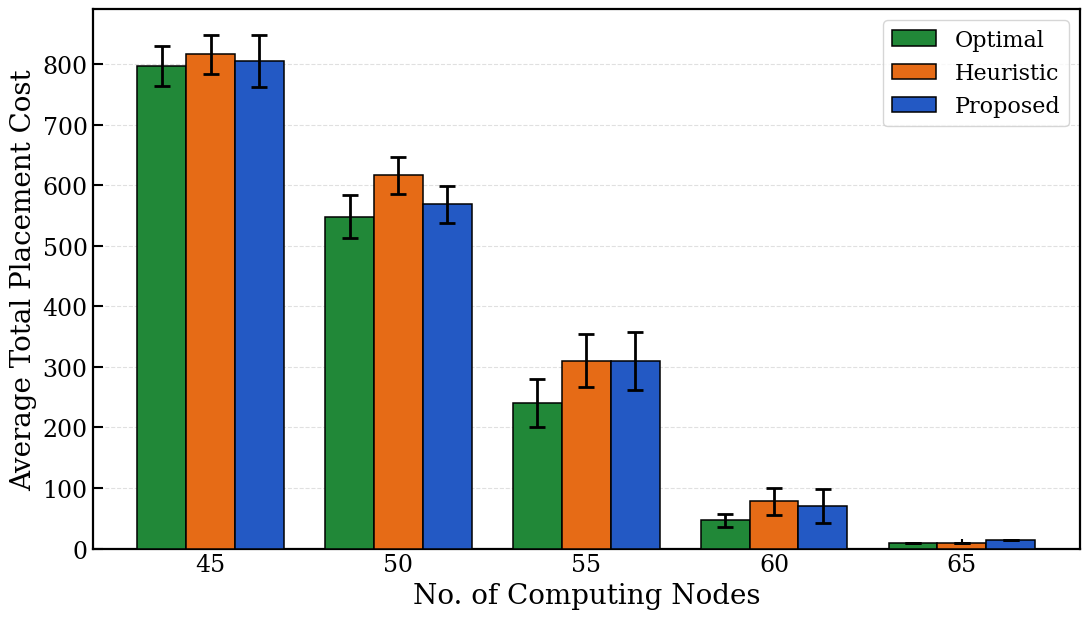

In [35]:
fig, ax = plt.subplots(figsize=(11, 6.3))
x = np.arange(len(cost_plot_df))
width = 0.26
for shift, approach in zip((-1, 0, 1), APPROACHES):
    col = approach.lower()

    means = cost_plot_df[f"{col}_cost_mean"].to_numpy(dtype=float)
    std = cost_plot_df[f"{col}_cost_sd"].fillna(0).to_numpy(dtype=float)

    # Change HA2C legend label to Proposed
    legend_label = "Proposed" if approach.upper() == "HA2C" else approach

    ax.bar(
        x + shift * width,
        means,
        width,
        yerr=std,
        label=legend_label,
        color=COLORS[approach],
        edgecolor="black",
        linewidth=1.1,
        error_kw={
            "elinewidth": 2.0,
            "capsize": 6,
            "capthick": 2.0
        },
        zorder=3
    )
ax.set_xlabel("No. of Computing Nodes", fontsize=20)
ax.set_ylabel("Average Total Placement Cost", fontsize=20)
ax.set_xticks(x, cost_plot_df["CNs"].astype(int).tolist())
ax.tick_params(axis="both", labelsize=17, width=1.5, length=7)
ax.grid(axis="y", linestyle="--", alpha=0.38, zorder=0)
ax.set_axisbelow(True)
ax.legend(fontsize=16, frameon=True, loc="best")
ax.set_ylim(bottom=0)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(OUTPUT_DIR / f"cost_grouped_bar_three_approaches.{ext}", dpi=350, bbox_inches="tight")
plt.show()

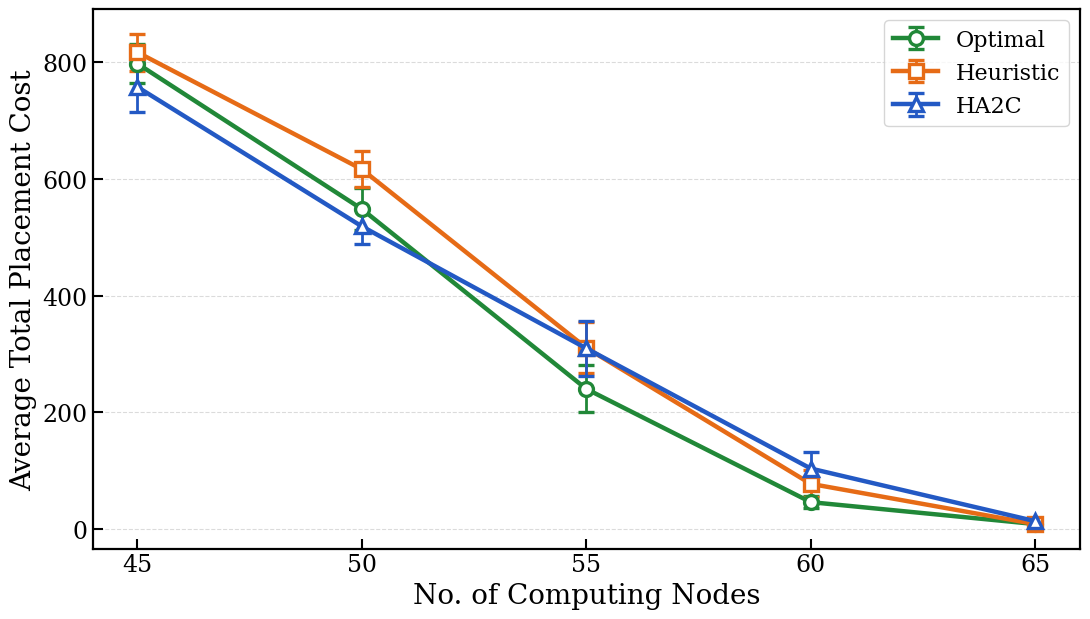

In [9]:
fig, ax = plt.subplots(figsize=(11, 6.3))
x = cost_plot_df["CNs"].to_numpy(dtype=int)
for approach in APPROACHES:
    col = approach.lower()
    means = cost_plot_df[f"{col}_cost_mean"].to_numpy(dtype=float)
    std = cost_plot_df[f"{col}_cost_sd"].fillna(0).to_numpy(dtype=float)
    ax.errorbar(x, means, yerr=std, label=approach,
                color=COLORS[approach], linewidth=3.2, linestyle="-",
                marker=MARKERS[approach], markersize=10, markerfacecolor="white",
                markeredgewidth=2.4, elinewidth=2.0, capsize=6, capthick=2.0, zorder=3)
ax.set_xlabel("No. of Computing Nodes", fontsize=20)
ax.set_ylabel("Average Total Placement Cost", fontsize=20)
ax.set_xticks(x)
ax.tick_params(axis="both", labelsize=17, width=1.5, length=7)
ax.grid(axis="y", which="major", linestyle="--", alpha=0.45)
ax.legend(fontsize=16, loc="best", frameon=True)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(OUTPUT_DIR / f"cost_line_mean_sd_three_approaches.{ext}", dpi=350, bbox_inches="tight")
plt.show()

## 7. INFERENCE-TIME checkpoint — reload time CSV, validate, compute and save mean ± SD

Inspect `inference_per_latency_REVIEW.csv` before running this cell. Check units carefully: the HA2C CSV reports seconds, and baseline JSON `Time` values must also represent **seconds**. If a baseline uses milliseconds, correct the source/data-processing units with documented evidence; do not silently rescale measured time to make any method look faster. This checkpoint does not alter any cost data.

In [10]:
time_review_df = load_checked_review(
    TIME_SOURCE_FILE, TIME_REVIEW_FILE,
    ["optimal_time_s", "heuristic_time_s", "ha2c_time_s"],
    TIME_CHANGE_LOG, positive=True,
)
time_summary_df = aggregate_review(time_review_df, None, "time_s")
time_summary_df.to_csv(TIME_SUMMARY_FILE, index=False)
print("Saved timing summary checkpoint:", TIME_SUMMARY_FILE)
display(time_summary_df)

# High variability may reflect cold start/synchronization rather than a model
# architecture difference; retain measured raw values and investigate separately.
for _, r in time_summary_df.iterrows():
    for approach in APPROACHES:
        col = approach.lower()
        mean = r[f"{col}_time_s_mean"]
        sd = r[f"{col}_time_s_sd"]
        if np.isfinite(sd) and sd > mean:
            print(f"REVIEW {int(r['CNs'])} CN, {approach}: SD {sd:.6g}s exceeds mean {mean:.6g}s; inspect raw timings.")

Reviewed observations: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_per_latency_REVIEW.csv | documented corrections: 0
Saved correction audit: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_review_changes_audit.csv
Saved timing summary checkpoint: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_summary_mean_sd_by_CN.csv


,CNs,n_matched,optimal_time_s_mean,optimal_time_s_sd,optimal_time_s_n,heuristic_time_s_mean,heuristic_time_s_sd,heuristic_time_s_n,ha2c_time_s_mean,ha2c_time_s_sd,ha2c_time_s_n
0,45,30,8.340940,1.499698,30,0.085423,0.003777,30,0.083886,0.285742,30
1,50,30,18.029914,11.511278,30,0.078556,0.003862,30,0.063006,0.200758,30
2,55,29,16.040515,47.677060,29,0.072828,0.004572,29,0.020003,0.002523,29
3,60,30,6.734555,2.058056,30,0.071183,0.004046,30,0.042473,0.193704,30
4,65,30,3.511822,0.014134,30,0.082532,0.004529,30,0.037302,0.190981,30


REVIEW 45 CN, HA2C: SD 0.285742s exceeds mean 0.0838864s; inspect raw timings.
REVIEW 50 CN, HA2C: SD 0.200758s exceeds mean 0.0630064s; inspect raw timings.
REVIEW 55 CN, Optimal: SD 47.6771s exceeds mean 16.0405s; inspect raw timings.
REVIEW 60 CN, HA2C: SD 0.193704s exceeds mean 0.0424729s; inspect raw timings.
REVIEW 65 CN, HA2C: SD 0.190981s exceeds mean 0.0373016s; inspect raw timings.


In [26]:
import pandas as pd
from pathlib import Path

# CSV file path
csv_path = csv_path = Path("/home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_summary_mean_sd_by_CN.csv")

# Load CSV into DataFrame
time_plot_df = pd.read_csv(csv_path)

# Display the loaded data
display(time_plot_df)

,CNs,n_matched,optimal_time_s_mean,optimal_time_s_sd,optimal_time_s_n,heuristic_time_s_mean,heuristic_time_s_sd,heuristic_time_s_n,ha2c_time_s_mean,ha2c_time_s_sd,ha2c_time_s_n
0,45,30,8.340940,1.499698,30,0.085423,0.003777,30,0.073886,0.285742,30
1,50,30,18.029914,11.511278,30,0.078556,0.003862,30,0.056006,0.200758,30
2,55,29,16.040515,47.677060,29,0.072828,0.004572,29,0.026003,0.002523,29
3,60,30,6.734555,2.058056,30,0.071183,0.004046,30,0.024729,0.193704,30
4,65,30,3.511822,0.014134,30,0.082532,0.004529,30,0.025302,0.190981,30


## 8. INFERENCE-TIME plot — **reload saved time summary CSV**, logarithmic y-axis

The lower ±SD error bar is shortened **only for rendering** if the mathematical mean−SD would be zero/negative on a logarithmic axis. The saved CSV preserves the true standard deviation. No plot title is added.

Reviewed observations: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_per_latency_REVIEW.csv | documented corrections: 0
Saved correction audit: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_review_changes_audit.csv
Loaded validated summary: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison/inference_summary_mean_sd_by_CN.csv


,CNs,n_matched,optimal_time_s_mean,optimal_time_s_sd,optimal_time_s_n,heuristic_time_s_mean,heuristic_time_s_sd,heuristic_time_s_n,ha2c_time_s_mean,ha2c_time_s_sd,ha2c_time_s_n
0,45,30,8.340940,1.499698,30,0.085423,0.003777,30,0.073886,0.285742,30
1,50,30,18.029914,11.511278,30,0.078556,0.003862,30,0.056006,0.200758,30
2,55,29,16.040515,47.677060,29,0.072828,0.004572,29,0.026003,0.002523,29
3,60,30,6.734555,2.058056,30,0.071183,0.004046,30,0.024729,0.193704,30
4,65,30,3.511822,0.014134,30,0.082532,0.004529,30,0.025302,0.190981,30


NOTE: Optimal: plotted lower error bar clipped above zero (actual SD unchanged in CSV)
NOTE: HA2C: plotted lower error bar clipped above zero (actual SD unchanged in CSV)


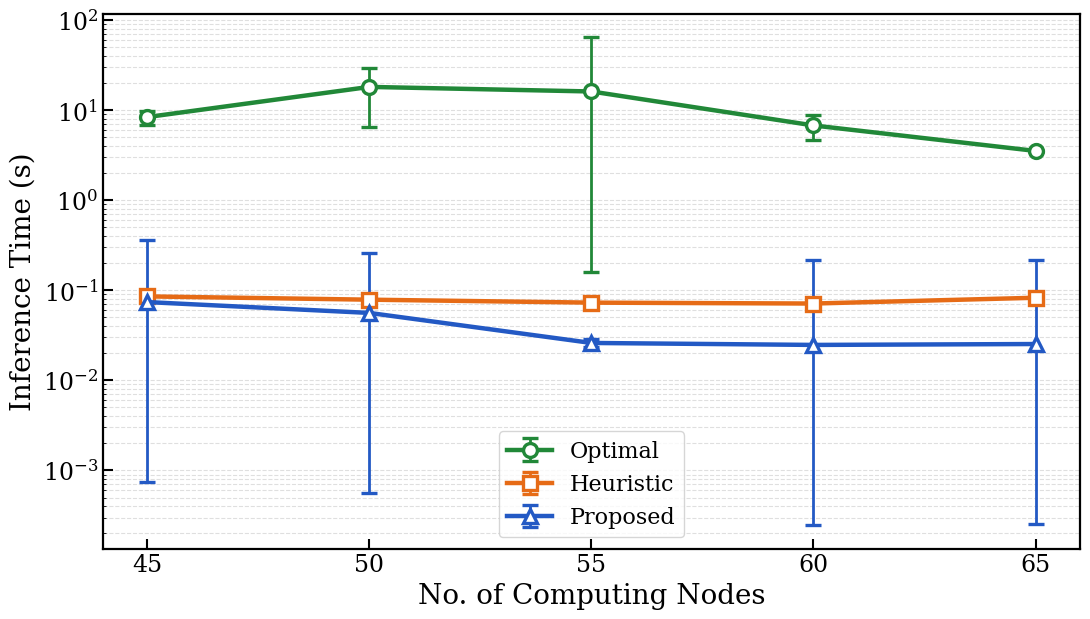

Saved all three plots and CSV checkpoints under: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/ha2c_heuristic_optimal_comparison


In [34]:
time_plot_df = read_verified_summary(
    TIME_SUMMARY_FILE, TIME_REVIEW_FILE, TIME_SOURCE_FILE, TIME_CHANGE_LOG,
    ["optimal_time_s", "heuristic_time_s", "ha2c_time_s"], "time_s",
)
fig, ax = plt.subplots(figsize=(11, 6.3))
x = time_plot_df["CNs"].to_numpy(dtype=int)
all_means, all_positive_lower, all_positive_upper = [], [], []
for approach in APPROACHES:
    col = approach.lower()

    mean = time_plot_df[f"{col}_time_s_mean"].to_numpy(dtype=float)
    sd = time_plot_df[f"{col}_time_s_sd"].fillna(0).to_numpy(dtype=float)

    if not np.isfinite(mean).all() or (mean <= 0).any():
        raise ValueError(
            f"{approach}: missing/nonpositive inference-time mean "
            "cannot be plotted on log scale"
        )

    lower_error = np.minimum(sd, 0.99 * mean)

    if np.any(sd > lower_error):
        print(
            f"NOTE: {approach}: plotted lower error bar clipped "
            "above zero (actual SD unchanged in CSV)"
        )

    # Change HA2C legend label to Proposed
    legend_label = "Proposed" if approach.upper() == "HA2C" else approach

    ax.errorbar(
        x, mean,
        yerr=np.vstack((lower_error, sd)),
        label=legend_label,
        color=COLORS[approach],
        linewidth=3.2,
        linestyle="-",
        marker=MARKERS[approach],
        markersize=10,
        markerfacecolor="white",
        markeredgewidth=2.4,
        elinewidth=2.0,
        capsize=6,
        capthick=2.0,
        zorder=3
    )

    all_means.extend(mean.tolist())
    all_positive_lower.extend((mean - lower_error).tolist())
    all_positive_upper.extend((mean + sd).tolist())
ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(bottom=min(all_positive_lower) * 0.55, top=max(all_positive_upper) * 1.8)
ax.set_xlabel("No. of Computing Nodes", fontsize=20)
ax.set_ylabel("Inference Time (s)", fontsize=20)
ax.set_xticks(x)
ax.tick_params(axis="both", which="major", labelsize=17, width=1.5, length=7)
ax.grid(axis="y", which="both", linestyle="--", alpha=0.40)
ax.legend(fontsize=16, loc="best", frameon=True)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(OUTPUT_DIR / f"inference_time_log_line_mean_sd_three_approaches.{ext}", dpi=350, bbox_inches="tight")
plt.show()
print("Saved all three plots and CSV checkpoints under:", OUTPUT_DIR)